# Follow pitch through a recording, without using labels to select windows
Our question: does the candidate frequency follow E2 → F2 → F#2, and what
happens during the attacks and fading tails? Keep every candidate visible.
This is a continuous analysis prototype, not yet note-event or tab generation.

Architecture: WAV → samples → overlapping windows → pitch/RMS/similarity rows
→ plots and CSV. `pitch_analysis.py` contains the reusable single-window
calculation. This notebook owns the explicit loop and plots. MIDI enters only
AFTER all audio measurements are complete, as a comparison layer.

## 1. Load the same short recording
Read 0–11.9 s from P1's direct-input WAV. Use its actual sample rate (48 kHz).
Keep original sample indices so every plotted estimate can be traced to audio.
No new dependencies; use the Guitar ML (.venv) kernel and run from this folder.


In [1]:
from pathlib import Path
import csv
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from pitch_analysis import estimate_period

dataset_folder = Path.home() / "Downloads/P1_singlenotes"
audio_path = dataset_folder / "audio/directinput/directinput_allsinglenotes.wav"
excerpt_start_seconds = 0.0
excerpt_stop_seconds = 11.9
info = sf.info(audio_path)
sample_rate = info.samplerate
excerpt_start_sample = round(excerpt_start_seconds * sample_rate)
excerpt_stop_sample = round(excerpt_stop_seconds * sample_rate)
if not 0 <= excerpt_start_sample < excerpt_stop_sample <= info.frames:
    raise ValueError("Choose an excerpt entirely inside the WAV.")
audio, sample_rate = sf.read(audio_path, start=excerpt_start_sample, stop=excerpt_stop_sample)
signal = audio[:, 0] if audio.ndim == 2 else audio
if not np.all(np.isfinite(signal)):
    raise ValueError("Audio contains nonfinite samples.")
print(f"{audio_path.name}: {sample_rate:,} samples/second")
print(f"Original excerpt samples [{excerpt_start_sample}:{excerpt_stop_sample}]")


directinput_allsinglenotes.wav: 48,000 samples/second
Original excerpt samples [0:571200]


## 2. Define the window and hop separately
A 100 ms window contains 4,800 samples at 48 kHz; a 20 ms hop advances 960
samples. Consecutive windows overlap by 80 ms (3,840 samples). These are trial
settings, not proven optimal values. Short windows follow changes but contain
fewer cycles, making pitch estimates harder. At 82 Hz, 100 ms is only ~8 cycles.

`range(0, len(signal) - window_samples + 1, hop_samples)` visits every full
window. The `+1` includes a window ending exactly at the excerpt boundary.
A final incomplete window is dropped, never filled with zeros. For this excerpt
the last full window ends exactly at the boundary, so no tail is dropped.
Each point is placed at its window midpoint. A 20 ms hop is not a guarantee of
20 ms onset accuracy: each estimate still summarizes 100 ms of audio.


In [2]:
window_seconds = 0.100
hop_seconds = 0.020
minimum_frequency = 60.0
maximum_frequency = 1000.0
window_samples = round(window_seconds * sample_rate)
hop_samples = round(hop_seconds * sample_rate)
if window_samples <= 0 or hop_samples <= 0 or window_samples > len(signal):
    raise ValueError("Choose positive window/hop sizes and an excerpt at least one window long.")
window_starts = range(0, len(signal) - window_samples + 1, hop_samples)
print(f"Window: {window_samples} samples ({window_samples / sample_rate:.3f} s)")
print(f"Hop: {hop_samples} samples ({hop_samples / sample_rate:.3f} s)")
print(f"Complete windows: {len(window_starts)}")
print(f"Search: {minimum_frequency:g}–{maximum_frequency:g} Hz, unchanged for every window")


Window: 4800 samples (0.100 s)
Hop: 960 samples (0.020 s)
Complete windows: 591
Search: 60–1000 Hz, unchanged for every window


## 3. The sliding loop — audio only
`local_start` indexes the loaded excerpt. Adding `excerpt_start_sample` gives
the index in the original WAV. RMS is computed on the original window; the
pitch function subtracts its mean internally to compare repeating patterns.

The function returns candidate Hz, the selected lag, and similarity. A constant
window or no positive local peak gives NaN (no candidate). That mathematical
exception is NOT a learned or threshold-based noise detector. Quiet noise may
still produce a frequency and a high similarity score. No smoothing, label-based
correction, clipping of wrong guesses, or RMS/similarity rejection is applied.

Each row is an observation window, not a separate played note. Adjacent rows
overlap and are not independent test examples. We will inspect them before
deciding whether a simple no-reliable-pitch rule is needed.


In [3]:
rows = []
for local_start in window_starts:
    window = signal[local_start:local_start + window_samples]
    candidate_hz, lag, score = estimate_period(
        window, sample_rate, minimum_frequency, maximum_frequency)
    original_start = excerpt_start_sample + local_start
    original_stop = original_start + window_samples
    rows.append(dict(
        dataset=dataset_folder.name,
        source_file=audio_path.name,
        sample_rate=sample_rate,
        start_sample=original_start,
        stop_sample_exclusive=original_stop,
        midpoint_seconds=(original_start + original_stop) / (2 * sample_rate),
        rms=float(np.sqrt(np.mean(window ** 2))),
        candidate_hz=float(candidate_hz),
        lag_samples=float(lag),
        similarity=float(score),
    ))

times = np.array([row["midpoint_seconds"] for row in rows])
pitches = np.array([row["candidate_hz"] for row in rows])
rms = np.array([row["rms"] for row in rows])
scores = np.array([row["similarity"] for row in rows])
print(f"Computed {len(rows)} windows; {np.isfinite(pitches).sum()} have mathematical pitch candidates.")
print("This count is not a count of reliable notes.")
print("First row:", rows[0])
print("Last row:", rows[-1])


Computed 591 windows; 590 have mathematical pitch candidates.
This count is not a count of reliable notes.
First row: {'dataset': 'P1_singlenotes', 'source_file': 'directinput_allsinglenotes.wav', 'sample_rate': 48000, 'start_sample': 0, 'stop_sample_exclusive': 4800, 'midpoint_seconds': 0.05, 'rms': 0.01747561885753601, 'candidate_hz': 82.90155440414507, 'lag_samples': 579.0, 'similarity': 0.8719881937284201}
Last row: {'dataset': 'P1_singlenotes', 'source_file': 'directinput_allsinglenotes.wav', 'sample_rate': 48000, 'start_sample': 566400, 'stop_sample_exclusive': 571200, 'midpoint_seconds': 11.85, 'rms': 0.00011502776228545016, 'candidate_hz': 888.8888888888889, 'lag_samples': 54.0, 'similarity': 0.3082602137663272}


## 4. Add MIDI references after prediction
Only now load the MIDI annotations. The same audio loop works without them.
Missing MIDI only removes the comparison overlay; it does not block analysis.
We keep the original label times, including any misalignment seen in lesson 03.
A gap between labels is not proof of acoustic silence: ringing may continue.


In [4]:
labels = []
midi_path = dataset_folder / "midi/midi_allsinglenotes.mid"
if midi_path.exists():
    from guitartechs_midi import read_note_labels
    all_labels, _ = read_note_labels(midi_path)
    labels = [note for note in all_labels
              if note["end_seconds"] > excerpt_start_sample / sample_rate
              and note["start_seconds"] < excerpt_stop_sample / sample_rate]
    pitch_names = ("C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B")
    for note in labels:
        pitch = note["midi_note"]
        note["name"] = f"{pitch_names[pitch % 12]}{pitch // 12 - 1}"
        note["label_hz"] = 440 * 2 ** ((pitch - 69) / 12)
    print(f"Loaded {len(labels)} reference labels after completing all estimates.")
else:
    print("No MIDI file: showing the audio measurements without reference labels.")


Loaded 3 reference labels after completing all estimates.


## 5. Read pitch, level, and similarity together
Orange dots show ALL finite candidates; blue lines are supplied MIDI frequencies.
The frequency axis is logarithmic so octave jumps remain visible without
cropping high-frequency mistakes. Each dot summarizes a complete 100 ms window.

RMS is displayed in dBFS: `20 * log10(RMS)`. RMS 0.1 gives -20 dBFS; RMS 0.01
gives -40 dBFS. More negative means weaker digital signal, not lower pitch.
For plotting only, zero/tiny RMS is floored at 1e-12 (-240 dBFS); the CSV keeps
original RMS. This scale makes faint tails visible without normalizing the WAV.
Similarity near 1 means repeating waveform structure, not certainty about a note.
Shorter windows also lower this particular score: at lag k, only N-k of N
samples overlap. A strong repeat near 580 samples in a 4,800-sample window
can score around 0.88, versus roughly 0.98 in a half-second window. Do not
transfer similarity thresholds between window lengths without checking them.

Inspect early ringing, each fading tail, and the transitions near 4 and 8 seconds.
Look for octave jumps or stable-looking pitches at very low RMS. Do not tune a
threshold simply to match this one recording or assume all label gaps are silent.


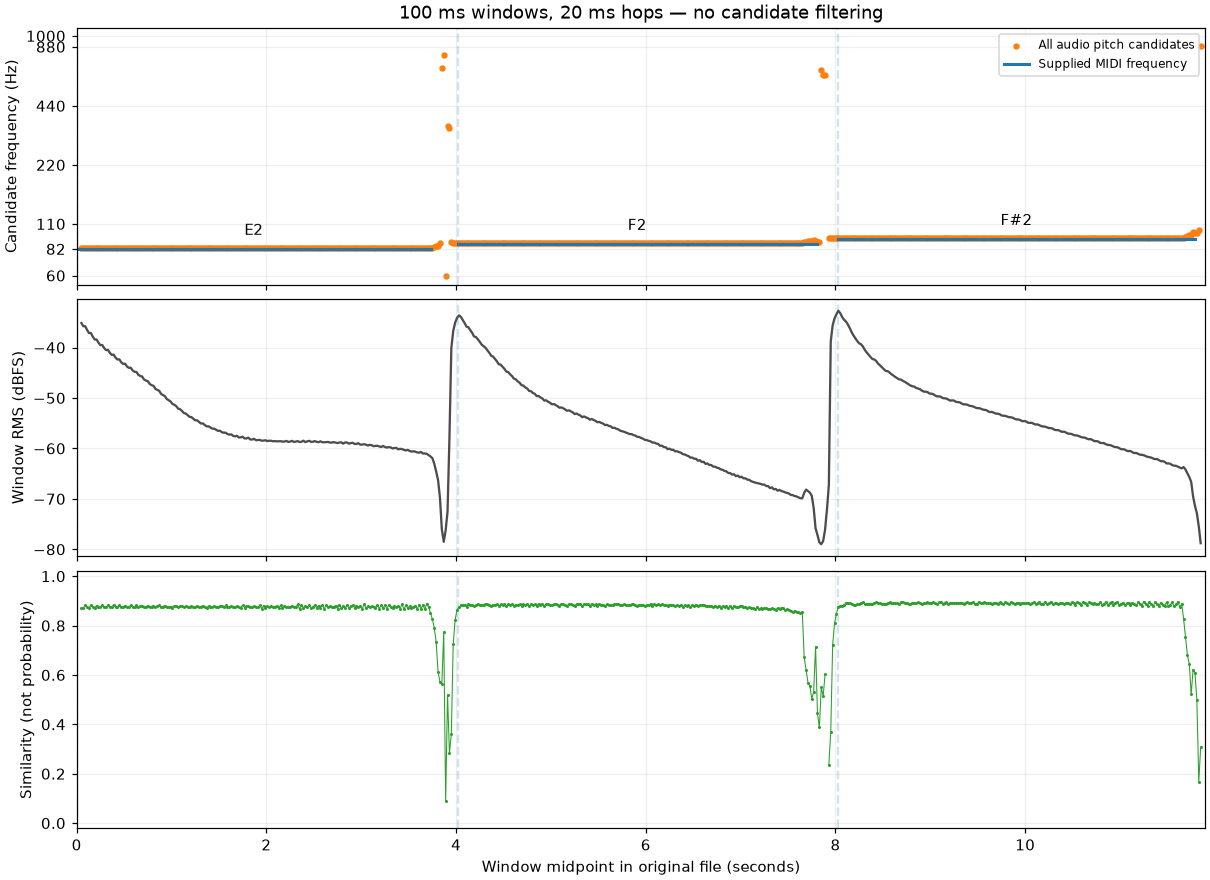

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
axes[0].scatter(times, pitches, s=10, color="tab:orange", label="All audio pitch candidates")
for index, note in enumerate(labels):
    first = max(note["start_seconds"], excerpt_start_sample / sample_rate)
    last = min(note["end_seconds"], excerpt_stop_sample / sample_rate)
    axes[0].plot([first, last], [note["label_hz"]] * 2, color="tab:blue", linewidth=2,
                 label="Supplied MIDI frequency" if index == 0 else None)
    axes[0].annotate(note["name"], ((first + last) / 2, note["label_hz"]),
                     xytext=(0, 9), textcoords="offset points", ha="center")
axes[0].set(yscale="log", ylim=(minimum_frequency * 0.9, maximum_frequency * 1.1),
            ylabel="Candidate frequency (Hz)", title="100 ms windows, 20 ms hops — no candidate filtering")
axes[0].set_yticks([60, 82, 110, 220, 440, 880, 1000],
                   labels=["60", "82", "110", "220", "440", "880", "1000"])
axes[0].minorticks_off()
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(times, 20 * np.log10(np.maximum(rms, 1e-12)), color="0.3")
axes[1].set(ylabel="Window RMS (dBFS)")
axes[2].plot(times, scores, color="tab:green", marker=".", markersize=2, linewidth=0.7)
axes[2].set(ylabel="Similarity (not probability)", xlabel="Window midpoint in original file (seconds)",
            ylim=(-0.02, 1.02))
for ax in axes:
    ax.set_xlim(excerpt_start_sample / sample_rate, excerpt_stop_sample / sample_rate)
    ax.grid(alpha=0.2)
    for note in labels:
        ax.axvline(note["start_seconds"], color="tab:blue", alpha=0.2, linestyle="--")
plt.show()


## 6. Save measurements for inspection
The CSV has one row per window and the exact original sample boundaries. It
contains audio-derived measurements only, no MIDI-derived targets. It can be
regenerated and is ignored by Git. No notes have been grouped into events yet.


In [6]:
output_folder = Path("outputs/pitch_tracking")
output_folder.mkdir(parents=True, exist_ok=True)
output_path = output_folder / f"{dataset_folder.name}_windows.csv"
with output_path.open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
fig.savefig(output_folder / f"{dataset_folder.name}_pitch_tracking.png", dpi=150)
print("Saved:", output_path)


Saved: outputs/pitch_tracking/P1_singlenotes_windows.csv


Next: discuss what fails before adding a rejection rule. Still missing are
reliable note-presence decisions, attack detection, grouping windows into note
events, chord handling, and string/fret assignment. Shorter windows may favor
octave errors; the 60–1,000 Hz search excludes some higher guitar notes.
This first comparison does not establish accuracy on other performers or sounds.

Dataset: Pedroza et al., *Guitar-TECHS*, ICASSP 2025,
[official release](https://zenodo.org/records/14963133),
[project and CC BY 4.0 license](https://guitar-techs.github.io/).
